In [1]:
# Cell 1: Setup and Execution Device Configuration
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt
import numpy as np

# Configure active execution device (CUDA GPU)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Active Execution Device:", device)
if device.type == 'cuda':
    print("GPU Hardware Model:", torch.cuda.get_device_name(0))

Active Execution Device: cuda
GPU Hardware Model: Tesla T4


In [2]:
# Cell 2: Load MNIST Dataset and Apply Normalization to [-1, 1]
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])

train_dataset = torchvision.datasets.MNIST(root='./data', train=True, download=True, transform=transform)
test_dataset = torchvision.datasets.MNIST(root='./data', train=False, download=True, transform=transform)

train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=64, shuffle=False)

print(f"Training Dataset Samples: {len(train_dataset)}")
print(f"Testing Dataset Samples: {len(test_dataset)}")

100%|██████████| 9.91M/9.91M [00:00<00:00, 20.1MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 502kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 4.55MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 14.8MB/s]

Training Dataset Samples: 60000
Testing Dataset Samples: 10000


In [3]:
# Cell 3: Target CNN Architecture Definition
class CustomMNISTCNN(nn.Module):
    def __init__(self):
        super(CustomMNISTCNN, self).__init__()
        self.conv1 = nn.Conv2d(1, 32, kernel_size=3, padding=1)
        self.conv2 = nn.Conv2d(32, 64, kernel_size=3, padding=1)
        self.pool = nn.MaxPool2d(2, 2)
        self.dropout = nn.Dropout(0.25)
        self.fc1 = nn.Linear(64 * 7 * 7, 128)
        self.fc2 = nn.Linear(128, 10)

    def forward(self, x):
        x = self.pool(torch.relu(self.conv1(x)))
        x = self.pool(torch.relu(self.conv2(x)))
        x = x.view(-1, 64 * 7 * 7)
        x = torch.relu(self.fc1(x))
        x = self.dropout(x)
        return self.fc2(x)

model = CustomMNISTCNN().to(device)
print(model)

CustomMNISTCNN(
  (conv1): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv2): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (dropout): Dropout(p=0.25, inplace=False)
  (fc1): Linear(in_features=3136, out_features=128, bias=True)
  (fc2): Linear(in_features=128, out_features=10, bias=True)
)


In [4]:
# Cell 4: Train Baseline Classifier on Clean MNIST
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

print("Training baseline CNN model...")
for epoch in range(5):
    model.train()
    running_loss, correct, total = 0.0, 0, 0
    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        running_loss += loss.item()
        _, preds = torch.max(outputs, 1)
        correct += (preds == labels).sum().item()
        total += labels.size(0)
    print(f"Epoch {epoch+1}/5 | Loss: {running_loss/len(train_loader):.4f} | Acc: {correct/total*100:.2f}%")

# Clean Evaluation
model.eval()
clean_correct = 0
with torch.no_grad():
    for images, labels in test_loader:
        images, labels = images.to(device), labels.to(device)
        preds = model(images).argmax(dim=1)
        clean_correct += (preds == labels).sum().item()

clean_acc = clean_correct / len(test_dataset)
print(f"\nClean Test Set Accuracy: {clean_acc*100:.2f}%")

Training baseline CNN model...
Epoch 1/5 | Loss: 0.1789 | Acc: 94.47%
Epoch 2/5 | Loss: 0.0584 | Acc: 98.22%
Epoch 3/5 | Loss: 0.0447 | Acc: 98.63%
Epoch 4/5 | Loss: 0.0347 | Acc: 98.93%
Epoch 5/5 | Loss: 0.0284 | Acc: 99.07%

Clean Test Set Accuracy: 98.80%


In [5]:
# Cell 5: Adversarial Attack Functions
def fgsm_attack(images, labels, epsilon):
    images_req = images.clone().detach().requires_grad_(True)
    outputs = model(images_req)
    loss = criterion(outputs, labels)
    model.zero_grad()
    loss.backward()
    adv_images = images_req + epsilon * images_req.grad.sign()
    return torch.clamp(adv_images, -1, 1).detach()

def pgd_attack(images, labels, epsilon, alpha=None, iters=20):
    # Dynamically scale step size alpha to allow full traversal across epsilon bound
    if alpha is None:
        alpha = (2.5 * epsilon) / iters if epsilon > 0 else 0.01
    ori_images = images.clone().detach()
    adv_images = images.clone().detach() + torch.empty_like(images).uniform_(-epsilon, epsilon)
    adv_images = torch.clamp(adv_images, -1, 1)

    for _ in range(iters):
        adv_images.requires_grad = True
        outputs = model(adv_images)
        loss = criterion(outputs, labels)
        model.zero_grad()
        loss.backward()

        adv_images = adv_images + alpha * adv_images.grad.sign()
        eta = torch.clamp(adv_images - ori_images, -epsilon, epsilon)
        adv_images = torch.clamp(ori_images + eta, -1, 1).detach()

    return adv_images

def gaussian_noise_attack(images, sigma):
    noise = torch.randn_like(images) * sigma
    return torch.clamp(images + noise, -1, 1)

print("Attack functions loaded successfully.")

Attack functions loaded successfully.


Epsilon: 0.00 | FGSM Acc: 98.80% | PGD Acc: 98.80%
Epsilon: 0.05 | FGSM Acc: 97.46% | PGD Acc: 97.24%
Epsilon: 0.10 | FGSM Acc: 95.00% | PGD Acc: 93.95%
Epsilon: 0.15 | FGSM Acc: 91.15% | PGD Acc: 87.41%
Epsilon: 0.20 | FGSM Acc: 85.63% | PGD Acc: 75.21%
Epsilon: 0.25 | FGSM Acc: 78.11% | PGD Acc: 57.50%
Epsilon: 0.30 | FGSM Acc: 68.44% | PGD Acc: 35.30%


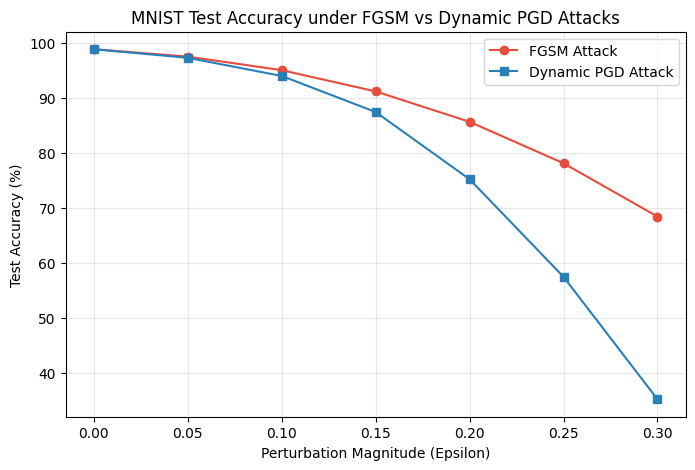

In [6]:
# Cell 6: Experiment 1 - Epsilon Sweep Comparison
epsilons = [0.0, 0.05, 0.10, 0.15, 0.20, 0.25, 0.30]
fgsm_accuracies, pgd_accuracies = [], []

for eps in epsilons:
    model.eval()
    fgsm_corr, pgd_corr = 0, 0
    for images, labels in test_loader:
        images, labels = images.to(device), labels.to(device)

        if eps == 0:
            fgsm_adv, pgd_adv = images, images
        else:
            fgsm_adv = fgsm_attack(images, labels, eps)
            pgd_adv = pgd_attack(images, labels, eps, iters=20)

        fgsm_corr += (model(fgsm_adv).argmax(dim=1) == labels).sum().item()
        pgd_corr += (model(pgd_adv).argmax(dim=1) == labels).sum().item()

    f_acc = fgsm_corr / len(test_dataset)
    p_acc = pgd_corr / len(test_dataset)
    fgsm_accuracies.append(f_acc)
    pgd_accuracies.append(p_acc)
    print(f"Epsilon: {eps:.2f} | FGSM Acc: {f_acc*100:.2f}% | PGD Acc: {p_acc*100:.2f}%")

plt.figure(figsize=(8, 5))
plt.plot(epsilons, [a*100 for a in fgsm_accuracies], marker='o', color='#E74C3C', label='FGSM Attack')
plt.plot(epsilons, [a*100 for a in pgd_accuracies], marker='s', color='#2980B9', label='Dynamic PGD Attack')
plt.title('MNIST Test Accuracy under FGSM vs Dynamic PGD Attacks')
plt.xlabel('Perturbation Magnitude (Epsilon)')
plt.ylabel('Test Accuracy (%)')
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

PGD Iterations N= 5 (alpha=0.1500) | Test Acc: 42.45%
PGD Iterations N=10 (alpha=0.0750) | Test Acc: 37.19%
PGD Iterations N=20 (alpha=0.0375) | Test Acc: 35.35%
PGD Iterations N=40 (alpha=0.0187) | Test Acc: 34.72%


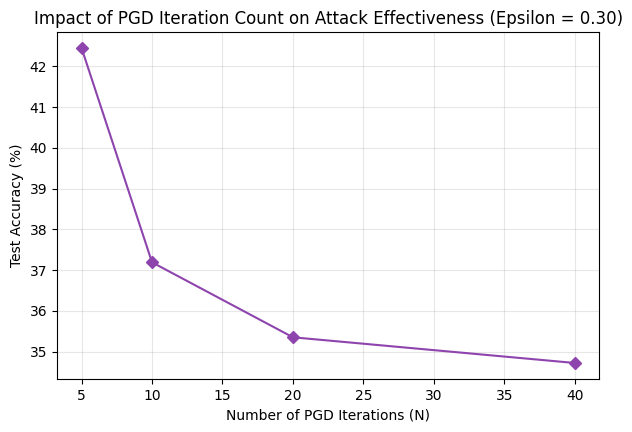

In [7]:
# Cell 7: Experiment 2 - PGD Iteration Depth Sensitivity
iters_list = [5, 10, 20, 40]
iter_accuracies = []

for n_iter in iters_list:
    model.eval()
    corr = 0
    alpha_step = (2.5 * 0.30) / n_iter
    for images, labels in test_loader:
        images, labels = images.to(device), labels.to(device)
        adv = pgd_attack(images, labels, epsilon=0.30, alpha=alpha_step, iters=n_iter)
        corr += (model(adv).argmax(dim=1) == labels).sum().item()
    acc = corr / len(test_dataset)
    iter_accuracies.append(acc)
    print(f"PGD Iterations N={n_iter:2d} (alpha={alpha_step:.4f}) | Test Acc: {acc*100:.2f}%")

plt.figure(figsize=(7, 4.5))
plt.plot(iters_list, [a*100 for a in iter_accuracies], marker='D', color='#8E44AD')
plt.title('Impact of PGD Iteration Count on Attack Effectiveness (Epsilon = 0.30)')
plt.xlabel('Number of PGD Iterations (N)')
plt.ylabel('Test Accuracy (%)')
plt.grid(True, alpha=0.3)
plt.show()

Bit Depth: 1-bit | Clean Acc: 98.40% | Recovered FGSM (eps=0.20) Acc: 95.83%
Bit Depth: 2-bit | Clean Acc: 98.72% | Recovered FGSM (eps=0.20) Acc: 94.66%
Bit Depth: 4-bit | Clean Acc: 98.80% | Recovered FGSM (eps=0.20) Acc: 86.84%
Bit Depth: 8-bit | Clean Acc: 98.80% | Recovered FGSM (eps=0.20) Acc: 86.02%


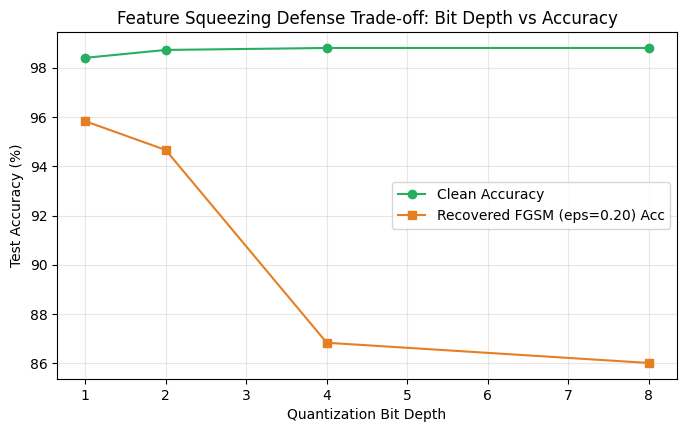

In [8]:
# Cell 8: Experiment 3 - Feature Squeezing Defense Trade-offs
def bit_depth_reduction(images, bits):
    levels = 2 ** bits
    norm_img = (images + 1.0) / 2.0
    quant_img = torch.floor(norm_img * (levels - 1) + 0.5) / (levels - 1)
    return (quant_img * 2.0) - 1.0

bit_depths = [1, 2, 4, 8]
clean_sq_accs, adv_sq_accs = [], []

for b in bit_depths:
    model.eval()
    c_corr, a_corr = 0, 0
    for images, labels in test_loader:
        images, labels = images.to(device), labels.to(device)
        adv = fgsm_attack(images, labels, epsilon=0.20)

        squeezed_clean = bit_depth_reduction(images, b)
        squeezed_adv = bit_depth_reduction(adv, b)

        c_corr += (model(squeezed_clean).argmax(dim=1) == labels).sum().item()
        a_corr += (model(squeezed_adv).argmax(dim=1) == labels).sum().item()

    c_acc = c_corr / len(test_dataset)
    a_acc = a_corr / len(test_dataset)
    clean_sq_accs.append(c_acc)
    adv_sq_accs.append(a_acc)
    print(f"Bit Depth: {b}-bit | Clean Acc: {c_acc*100:.2f}% | Recovered FGSM (eps=0.20) Acc: {a_acc*100:.2f}%")

plt.figure(figsize=(8, 4.5))
plt.plot(bit_depths, [a*100 for a in clean_sq_accs], marker='o', color='#27AE60', label='Clean Accuracy')
plt.plot(bit_depths, [a*100 for a in adv_sq_accs], marker='s', color='#E67E22', label='Recovered FGSM (eps=0.20) Acc')
plt.title('Feature Squeezing Defense Trade-off: Bit Depth vs Accuracy')
plt.xlabel('Quantization Bit Depth')
plt.ylabel('Test Accuracy (%)')
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

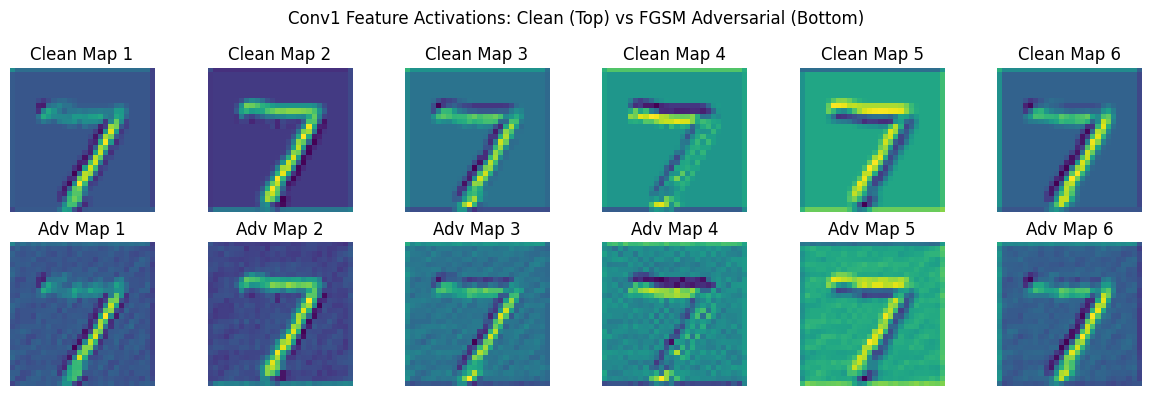

In [9]:
# Cell 9: Feature Activation Map Visualizations for Conv1 Layer
def get_conv1_activations(model, img_tensor):
    activations = {}
    def hook_fn(module, input, output):
        activations['conv1'] = output
    hook = model.conv1.register_forward_hook(hook_fn)
    with torch.no_grad():
        model(img_tensor)
    hook.remove()
    return activations['conv1']

model.eval()
images, labels = next(iter(test_loader))
clean_sample = images[0:1].to(device)
adv_sample = fgsm_attack(clean_sample, labels[0:1].to(device), epsilon=0.20)

clean_act = get_conv1_activations(model, clean_sample)
adv_act = get_conv1_activations(model, adv_sample)

fig, axes = plt.subplots(2, 6, figsize=(12, 4))
for i in range(6):
    axes[0, i].imshow(clean_act[0, i].cpu().numpy(), cmap='viridis')
    axes[0, i].set_title(f'Clean Map {i+1}')
    axes[0, i].axis('off')

    axes[1, i].imshow(adv_act[0, i].cpu().numpy(), cmap='viridis')
    axes[1, i].set_title(f'Adv Map {i+1}')
    axes[1, i].axis('off')

plt.suptitle('Conv1 Feature Activations: Clean (Top) vs FGSM Adversarial (Bottom)', fontsize=12)
plt.tight_layout()
plt.show()